            Model  Train Accuracy  Test Accuracy  Train-Test Gap
0        Baseline          0.9854         0.9500          0.0354
1        L2 0.001          0.9875         0.9500          0.0375
2         L2 0.01          0.9854         0.9500          0.0354
3          L2 0.1          0.9792         0.9750          0.0042
4     Dropout 0.2          0.9875         0.9417          0.0458
5     Dropout 0.3          0.9812         0.9417          0.0396
6     Dropout 0.5          0.9875         0.9500          0.0375
7  Early Stopping          0.9604         0.9500          0.0104


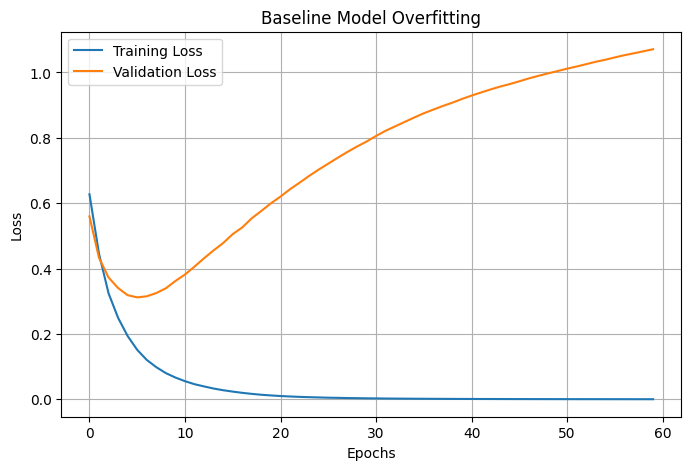

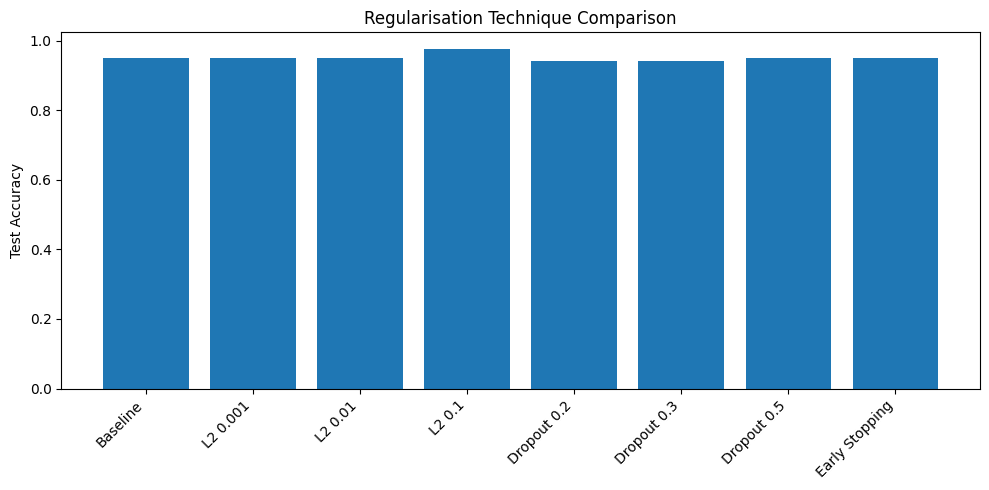

In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate diabetes-like dataset
X, y = make_classification(
    n_samples=600,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. Build model with regularisation options
def build_model(l2_value=0, dropout_rate=0, early=False):
    reg = tf.keras.regularizers.l2(l2_value)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(10,)),
        tf.keras.layers.Dense(256, activation="relu", kernel_regularizer=reg),
        tf.keras.layers.Dense(128, activation="relu", kernel_regularizer=reg),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

results = []
histories = {}

# 3. Baseline
configs = [
    ("Baseline", 0, 0, False),
    ("L2 0.001", 0.001, 0, False),
    ("L2 0.01", 0.01, 0, False),
    ("L2 0.1", 0.1, 0, False),
    ("Dropout 0.2", 0, 0.2, False),
    ("Dropout 0.3", 0, 0.3, False),
    ("Dropout 0.5", 0, 0.5, False),
    ("Early Stopping", 0, 0, True)
]

for name, l2_value, dropout, early in configs:
    model = build_model(l2_value, dropout)

    callbacks = []
    if early:
        callbacks.append(
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )
        )

    history = model.fit(
        X_train, y_train,
        epochs=60,
        batch_size=32,
        validation_split=0.2,
        callbacks=callbacks,
        verbose=0
    )

    train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    results.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Train-Test Gap": train_acc-test_acc
    })

    histories[name] = history.history

# 4. Display comparison table
results_df = pd.DataFrame(results)
print(results_df.round(4))

# 5. Plot baseline overfitting
plt.figure(figsize=(8, 5))
plt.plot(histories["Baseline"]["loss"], label="Training Loss")
plt.plot(histories["Baseline"]["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Baseline Model Overfitting")
plt.legend()
plt.grid()
plt.show()

# 6. Plot test accuracy comparison
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["Test Accuracy"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Test Accuracy")
plt.title("Regularisation Technique Comparison")
plt.tight_layout()
plt.show()
